Simulando el ensemble físico en NumPy...
0 / 20000
5000 / 20000
10000 / 20000
15000 / 20000


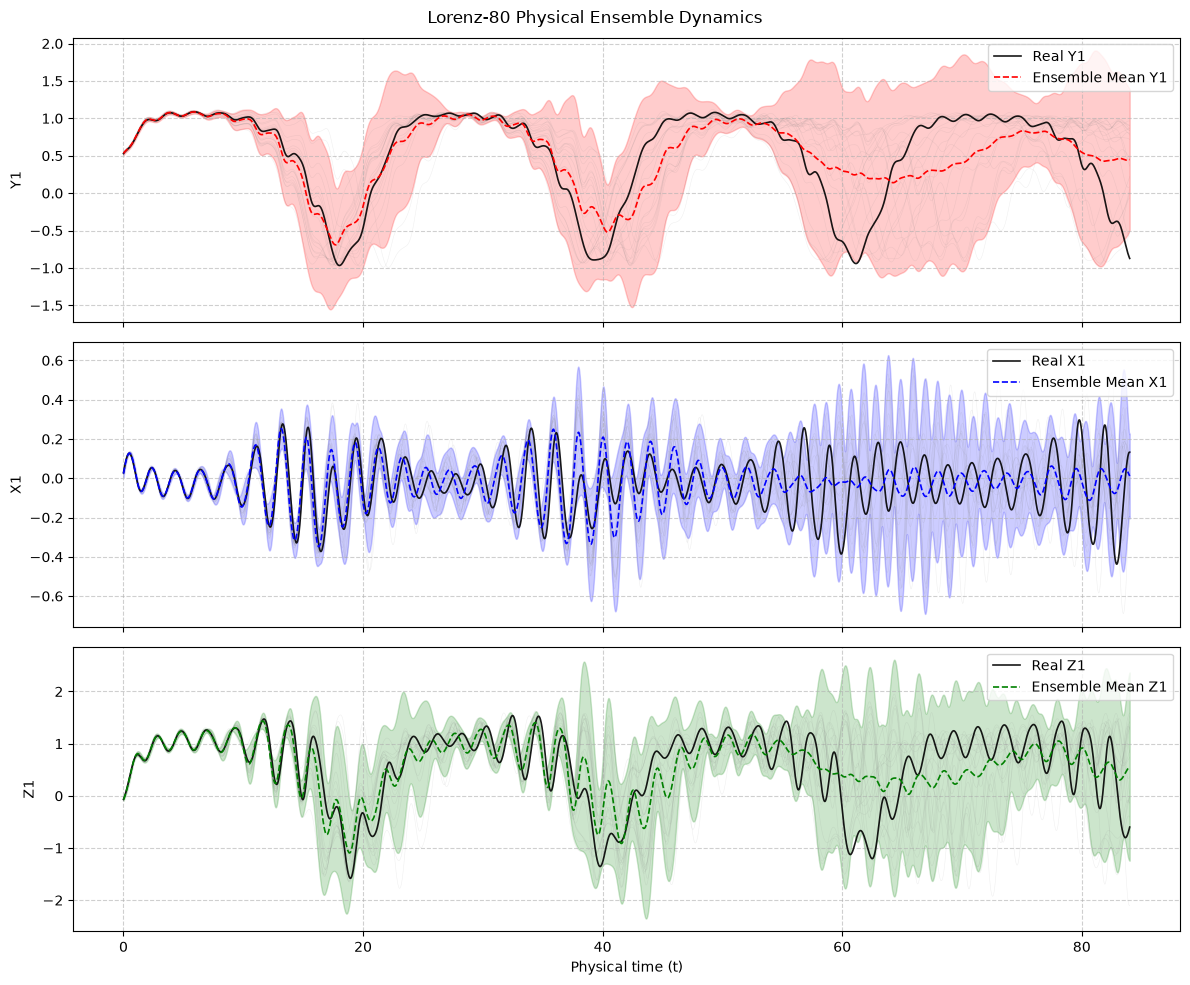

In [4]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt

# 1. Cargar datos reales de referencia
data = scipy.io.loadmat('../data/NN_training_data.mat')
raw_u = data['u']

# Parámetros del sistema Lorenz-80
a1, a2, a3 = 1.0, 1.0, 3.0
v0, k0 = 1 / 48.0, 1 / 48.0
b1 = (a1 - a2 - a3) / 2.0
b2 = (a2 - a3 - a1) / 2.0
b3 = (a3 - a1 - a2) / 2.0
c = np.sqrt(b1 * b2 + b2 * b3 + b3 * b1)

g0 = 8.0
h1, h2, h3 = -1.0, 0.0, 0.0
F1, F2, F3 = 0.3027, 0.0, 0.0

def dSdt_numpy(s):
    # s tiene forma (..., 9)
    x1, x2, x3 = s[..., 0], s[..., 1], s[..., 2]
    y1, y2, y3 = s[..., 3], s[..., 4], s[..., 5]
    z1, z2, z3 = s[..., 6], s[..., 7], s[..., 8]
    
    dx1dt = - v0 * a1**2 * x1 - c * (a1 - a3) * x2 * y3 + c * (a1 - a2) * y2 * x3 + a1 * b1 * x2 * x3 - 2 * c**2 * y2 * y3 + a1 * (y1 - z1)
    dx1dt = dx1dt / a1
    dx2dt = - v0 * a2**2 * x2 - c * (a2 - a1) * x3 * y1 + c * (a2 - a3) * y3 * x1 + a2 * b2 * x3 * x1 - 2 * c**2 * y3 * y1 + a2 * (y2 - z2)
    dx2dt = dx2dt / a2
    dx3dt = - v0 * a3**2 * x3 - c * (a3 - a2) * x1 * y2 + c * (a3 - a1) * y1 * x2 + a3 * b3 * x1 * x2 - 2 * c**2 * y1 * y2 + a3 * (y3 - z3)
    dx3dt = dx3dt / a3
    
    dy1dt = - a3 * b3 * x2 * y3 - a2 * b2 * y2 * x3 + c * (a3 - a2) * y2 * y3 - a1 * x1 - v0 * a1**2 * y1
    dy1dt = dy1dt / a1
    dy2dt = - a1 * b1 * x3 * y1 - a3 * b3 * y3 * x1 + c * (a1 - a3) * y3 * y1 - a2 * x2 - v0 * a2**2 * y2
    dy2dt = dy2dt / a2
    dy3dt = - a2 * b2 * x1 * y2 - a1 * b1 * y1 * x2 + c * (a2 - a1) * y1 * y2 - a3 * x3 - v0 * a3**2 * y3
    dy3dt = dy3dt / a3

    dz1dt = g0 * a1 * x1 - b3 * x2 * (z3 - h3) - b2 * x3 * (z2 - h2) + c * (z3 - h3) * y2 - c * (z2 - h2) * y3 - k0 * a1 * z1 + F1
    dz2dt = g0 * a2 * x2 - b1 * x3 * (z1 - h1) - b3 * x1 * (z3 - h3) + c * (z1 - h1) * y3 - c * (z3 - h3) * y1 - k0 * a2 * z2 + F2
    dz3dt = g0 * a3 * x3 - b2 * x1 * (z2 - h2) - b1 * x2 * (z1 - h1) + c * (z2 - h2) * y1 - c * (z1 - h1) * y2 - k0 * a3 * z3 + F3

    return np.stack([dx1dt, dx2dt, dx3dt, dy1dt, dy2dt, dy3dt, dz1dt, dz2dt, dz3dt], axis=-1)

def rk4_step_numpy(s, dt):
    k1 = dSdt_numpy(s)
    k2 = dSdt_numpy(s + 0.5 * dt * k1)
    k3 = dSdt_numpy(s + 0.5 * dt * k2)
    k4 = dSdt_numpy(s + dt * k3)
    return s + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# 2. Configuración del Ensemble Físico
M = 20          # 50 miembros en el ensemble
N = 20000        # Pasos temporales
dt = 4.2e-3
start_idx = 5030476

# Estado base real en el tiempo inicial
s_base = raw_u[:, start_idx]

# Perturbación minúscula para iniciar el efecto mariposa (1e-5)
np.random.seed(37)
initial_sigma_Y = 1e-2
s0_ensemble = s_base + np.random.randn(M, 9) * initial_sigma_Y

# 3. Bucle de integración del ensemble físico
ensemble_traj = np.zeros((N, M, 9))
current_s = s0_ensemble.copy()

print("Simulando el ensemble físico en NumPy...")
for step in range(N):
    ensemble_traj[step] = current_s
    current_s = rk4_step_numpy(current_s, dt)

    if step % 5000 == 0:
        print(f"{step} / {N}")

# Trayectoria real de referencia
real_traj = raw_u[:, start_idx : start_idx + N].T
t_axis = np.arange(N) * dt

# --- 4. Graficación Multi-panel del Ensemble Físico (Y1, X1, Z1) ---
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# 1. Variable Lenta Y1 (índice 3 en el vector de estado de 9 dimensiones)
for m in range(M):
    axes[0].plot(t_axis, ensemble_traj[:, m, 3], color='gray', alpha=0.12, linewidth=0.4)
mean_y1 = ensemble_traj[:, :, 3].mean(axis=1)
std_y1 = ensemble_traj[:, :, 3].std(axis=1)
axes[0].plot(t_axis, real_traj[:, 3], 'k-', label='Real Y1', alpha=0.9, linewidth=1.2)
axes[0].plot(t_axis, mean_y1, 'r--', label='Ensemble Mean Y1', linewidth=1.2)
axes[0].fill_between(t_axis, mean_y1 - 2 * std_y1, mean_y1 + 2 * std_y1, color='r', alpha=0.2)
axes[0].set_ylabel('Y1')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Variable Rápida X1 (índice 0 en el vector de estado de 9 dimensiones)
for m in range(M):
    axes[1].plot(t_axis, ensemble_traj[:, m, 0], color='gray', alpha=0.12, linewidth=0.4)
mean_x1 = ensemble_traj[:, :, 0].mean(axis=1)
std_x1 = ensemble_traj[:, :, 0].std(axis=1)
axes[1].plot(t_axis, real_traj[:, 0], 'k-', label='Real X1', alpha=0.9, linewidth=1.2)
axes[1].plot(t_axis, mean_x1, 'b--', label='Ensemble Mean X1', linewidth=1.2)
axes[1].fill_between(t_axis, mean_x1 - 2 * std_x1, mean_x1 + 2 * std_x1, color='b', alpha=0.2)
axes[1].set_ylabel('X1')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Variable Rápida Z1 (índice 6 en el vector de estado de 9 dimensiones)
for m in range(M):
    axes[2].plot(t_axis, ensemble_traj[:, m, 6], color='gray', alpha=0.12, linewidth=0.4)
mean_z1 = ensemble_traj[:, :, 6].mean(axis=1)
std_z1 = ensemble_traj[:, :, 6].std(axis=1)
axes[2].plot(t_axis, real_traj[:, 6], 'k-', label='Real Z1', alpha=0.9, linewidth=1.2)
axes[2].plot(t_axis, mean_z1, 'g--', label='Ensemble Mean Z1', linewidth=1.2)
axes[2].fill_between(t_axis, mean_z1 - 2 * std_z1, mean_z1 + 2 * std_z1, color='g', alpha=0.2)
axes[2].set_xlabel('Physical time (t)')
axes[2].set_ylabel('Z1')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Lorenz-80 Physical Ensemble Dynamics')
plt.tight_layout()
plt.savefig("../media/closed_loop/edo_model_dynamics.png")
plt.show()